# Porównanie przebiegów weryfikacji

**Po co.** Po prezentacji pipeline'u prowadzący zwrócił uwagę na trzy rzeczy: bge-m3 jest za słaby do wyszukiwania
w dokumentach naukowych, łączenie rankingów przez RRF jest niepotrzebne, a 69% werdyktów `brak_podstaw` to słabość
instrumentu. Notatnik zestawia przebiegi, w których zmieniono tylko krok werdyktu, żeby sprawdzić, czy któryś z nich
poprawia instrument.

**Co jest stałe.** Gemma 4 12B, tematyczność `topic_v0` i twierdzenia `claims_v1` z zamrożonego przebiegu (te same
1636 twierdzeń z wypowiedzi tematycznych), prompt werdyktu `verdict_v1` (RAG) albo `paperqa_v0` (PaperQA2: te same
reguły w szablonie pytania PaperQA). Zmienia się sposób wyszukiwania fragmentów AR6 (SPM i TS WGI–WGIII) albo całe
narzędzie do weryfikacji.

**Gold.** Ta sama próba 100 wypowiedzi, z warstwami i wagami z zamrożonego przebiegu. Odsetki z golda (krok 7) od
przebiegu nie zależą; zmienia się jakość etykiety modelu (krok 5), odsetki bez korekty i regresja (krok 6).
Gold liczony w dwóch wersjach: z repo (`HEAD`) i lokalnej (katalog roboczy, zmienione #22 i #94).

**Pliki.** Część wyników nie jest w repo (`data/processed/retrieval_variants.local/` i nieśledzone pliki
w `data/processed/verdicts/`); przebieg bez pliku notatnik pomija.

In [1]:
import subprocess
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(_root / "src"))

from amc import annotation as A, estimation as E, runs, viz
from amc.viz import INK2, MUTED, AXIS, ACCENT, SECOND, SURF, save

viz.setup()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
P = _root / "data" / "processed"
LOCAL = P / "retrieval_variants.local"
GROUPS = E.GROUPS
VERDICTS = ["brak_podstaw", "zgodne", "sprzeczne"]
FROZEN = "zamrożony"
REPS = 10_000

RUNS = pd.DataFrame([
    (FROZEN, "RAG", "RRF: bge-m3 PL + bge-m3 EN + BM25 EN", "bge-m3", "verdict_v1", "15.10", "0.40.4",
     P / "verdicts" / "verdict_v1__gemma4_12b.jsonl"),
    ("powtórka zamrożonego", "RAG", "RRF: bge-m3 PL + bge-m3 EN + BM25 EN", "bge-m3", "verdict_v1", "20.10", "0.40.4",
     LOCAL / "rrf_repeat.jsonl"),
    ("bge-m3 EN", "RAG", "gęste, tekst EN", "bge-m3", "verdict_v1", "20.10", "0.40.4", LOCAL / "dense_en.jsonl"),
    ("bge-m3 PL", "RAG", "gęste, tekst PL", "bge-m3", "verdict_v1", "20.10", "0.40.4", LOCAL / "dense_pl.jsonl"),
    ("BM25 EN", "RAG", "BM25, tekst EN", "—", "verdict_v1", "20.10", "0.40.4", LOCAL / "bm25.jsonl"),
    ("Qwen3-Embedding EN", "RAG", "gęste, tekst EN + instrukcja", "qwen3-embedding:8b", "verdict_v1", "20.10", "0.40.4",
     LOCAL / "qwen_en.jsonl"),
    ("EmbeddingGemma EN", "RAG", "gęste, tekst EN + prefiks", "embeddinggemma:300m", "verdict_v1", "26.10", "0.40.8",
     P / "verdicts" / "verdict_v1__gemma4_12b__en_embeddinggemma_300m.jsonl"),
    ("PaperQA2", "PaperQA2", "gęste po kawałkach PDF + streszczenia LLM", "embeddinggemma:300m", "paperqa_v0",
     "26–27.10", "0.40.8", P / "verdicts" / "paperqa_v0__gemma4_12b__embeddinggemma_300m.jsonl"),
], columns=["przebieg", "weryfikator", "wyszukiwanie", "embedding", "prompt", "data", "ollama", "plik"]).set_index("przebieg")
LABEL_FILES = {FROZEN: "gemma4_12b.csv", "EmbeddingGemma EN": "gemma4_12b__en_embeddinggemma_300m.csv",
               "PaperQA2": "gemma4_12b__paperqa_v0__embeddinggemma_300m.csv"}


def verdicts(path):
    d = pd.DataFrame(runs.last_lines(path, "twierdzenie_id").values()).set_index("twierdzenie_id")
    d["blad"] = d["blad"].notna()
    d.loc[d["blad"], "werdykt"] = np.nan
    return d


V = {}
for name, path in RUNS["plik"].items():
    if path.exists():
        V[name] = verdicts(path)
    else:
        print(f"pomijam {name}: brak pliku {path.relative_to(_root)}")
RUNS = RUNS.loc[list(V)]

labels = pd.read_csv(P / "labels" / "gemma4_12b.csv")
claims = pd.read_csv(P / "labels" / "gemma4_12b_claims.csv", usecols=["twierdzenie_id", "wypowiedz_id"])
design = pd.read_csv(_root / "data" / "gold" / "sample.csv")
POP = claims["twierdzenie_id"]
GOLD_CLAIMS = claims.loc[claims["wypowiedz_id"].isin(design["wypowiedz_id"]), "twierdzenie_id"]
FULL = [n for n, d in V.items() if POP.isin(d.index).all()]


def agree(a, b):
    ok = a.notna() & b.notna()
    return (a[ok] == b[ok]).mean()

## 1. Przebiegi

Wszystkie przebiegi RAG biorą po 3 fragmenty z SPM i 3 z TS (1786 ustaleń AR6). Zamrożony przebieg łączy trzy
rankingi przez RRF; warianty z 20.10 biorą jeden ranking. PaperQA2 dzieli pliki PDF na kawałki po 5000 znaków, szuka
ich embeddingiem, streszcza znalezione kawałki modelem i dopiero z tych streszczeń wydaje werdykt. Powtórka
zamrożonego (to samo wyszukiwanie, nowy przebieg) obejmuje tylko twierdzenia z golda i służy jako miara szumu
między przebiegami. Przebiegi z 20.10 i z 26–27.10 liczono na różnych wersjach Ollamy, co samo może zmieniać część
werdyktów.

In [2]:
RUNS.assign(plik=RUNS["plik"].map(lambda p: p.name), twierdzenia=[len(d) for d in V.values()],
            bledy=[int(d["blad"].sum()) for d in V.values()])

,weryfikator,wyszukiwanie,embedding,prompt,data,ollama,plik,twierdzenia,bledy
przebieg,,,,,,,,,
zamrożony,RAG,RRF: bge-m3 PL + bge-m3 EN + BM25 EN,bge-m3,verdict_v1,15.10,0.40.4,verdict_v1__gemma4_12b.jsonl,1636,0
powtórka zamrożonego,RAG,RRF: bge-m3 PL + bge-m3 EN + BM25 EN,bge-m3,verdict_v1,20.10,0.40.4,rrf_repeat.jsonl,139,0
bge-m3 EN,RAG,"gęste, tekst EN",bge-m3,verdict_v1,20.10,0.40.4,dense_en.jsonl,1636,0
bge-m3 PL,RAG,"gęste, tekst PL",bge-m3,verdict_v1,20.10,0.40.4,dense_pl.jsonl,1636,0
BM25 EN,RAG,"BM25, tekst EN",—,verdict_v1,20.10,0.40.4,bm25.jsonl,1636,0
Qwen3-Embedding EN,RAG,"gęste, tekst EN + instrukcja",qwen3-embedding:8b,verdict_v1,20.10,0.40.4,qwen_en.jsonl,1636,0
EmbeddingGemma EN,RAG,"gęste, tekst EN + prefiks",embeddinggemma:300m,verdict_v1,26.10,0.40.8,verdict_v1__gemma4_12b__en_embeddinggemma_300m...,1636,0
PaperQA2,PaperQA2,gęste po kawałkach PDF + streszczenia LLM,embeddinggemma:300m,paperqa_v0,26–27.10,0.40.8,paperqa_v0__gemma4_12b__embeddinggemma_300m.jsonl,1636,1


## 2. Werdykty na populacji

Te same 1636 twierdzeń w każdym przebiegu. Zgodność = odsetek twierdzeń z tym samym werdyktem co w zamrożonym
przebiegu; czas = mediana sekund na twierdzenie.

In [3]:
rows = {}
for n in FULL:
    d = V[n].loc[POP]
    shares = d["werdykt"].value_counts(normalize=True).reindex(VERDICTS, fill_value=0).mul(100)
    rows[n] = {"twierdzenia": len(d), **{f"{v} %": s for v, s in shares.items()},
               "zgodność z zamrożonym": agree(d["werdykt"], V[FROZEN].loc[POP, "werdykt"]),
               "mediana s / tw.": d["sekundy"].median()}
pop_shares = pd.DataFrame.from_dict(rows, orient="index")
pop_shares.round({**{f"{v} %": 1 for v in VERDICTS}, "zgodność z zamrożonym": 3, "mediana s / tw.": 1})

,twierdzenia,brak_podstaw %,zgodne %,sprzeczne %,zgodność z zamrożonym,mediana s / tw.
zamrożony,1636,69.4,24.1,6.4,1.000,3.2
bge-m3 EN,1636,69.7,24.3,6.0,0.909,3.0
bge-m3 PL,1636,69.7,24.1,6.2,0.905,3.0
BM25 EN,1636,73.4,21.8,4.8,0.890,3.0
Qwen3-Embedding EN,1636,66.6,25.6,7.8,0.883,3.1
EmbeddingGemma EN,1636,66.5,26.3,7.2,0.897,3.0
PaperQA2,1636,84.6,11.9,3.4,0.823,25.8


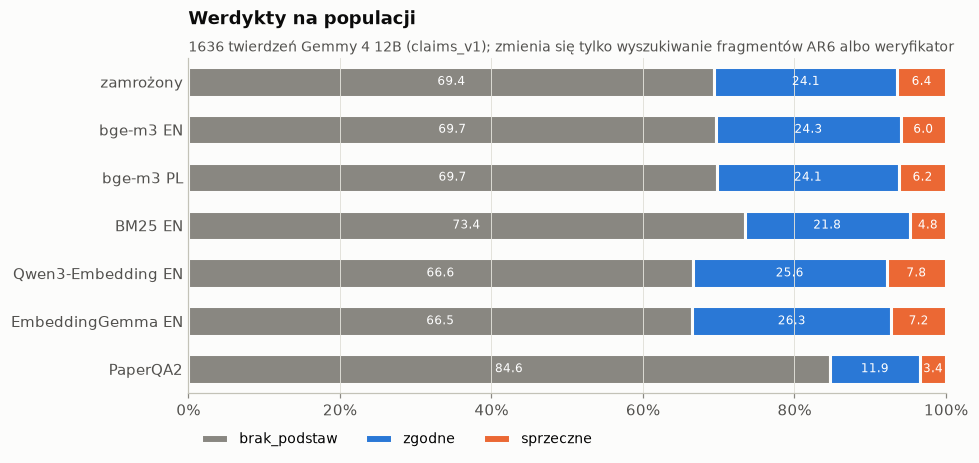

In [4]:
COLORS = {"brak_podstaw": MUTED, "zgodne": ACCENT, "sprzeczne": SECOND}
fig, ax = plt.subplots(figsize=(9, 0.42 * len(FULL) + 1.4))
y = np.arange(len(FULL))
left = np.zeros(len(FULL))
for v in VERDICTS:
    x = pop_shares[f"{v} %"].to_numpy(float)
    ax.barh(y, x, left=left, height=0.62, color=COLORS[v], edgecolor=SURF, linewidth=2, label=v)
    for yi, l, w in zip(y, left, x):
        if w >= 3:
            ax.text(l + w / 2, yi, f"{w:.1f}", ha="center", va="center", fontsize=8, color="white")
    left += x
ax.set_yticks(y, FULL)
ax.set_ylim(len(FULL) - 0.5, -0.5)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("Werdykty na populacji")
viz.subtitle(ax, "1636 twierdzeń Gemmy 4 12B (claims_v1); zmienia się tylko wyszukiwanie fragmentów AR6 albo weryfikator")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.08), fontsize=9)
fig.tight_layout()
save(fig, "weryfikacja_01_werdykty")

Żaden sposób wyszukiwania nie zmienia udziału `brak_podstaw` o więcej niż ok. 3–4 pp. Sam bge-m3 (EN albo PL) daje
to samo co RRF (69,7% vs 69,4%), sam BM25 więcej `brak_podstaw` (73,4%), Qwen3-Embedding i EmbeddingGemma o ok. 3 pp
mniej (66,6% i 66,5%), z przesunięciem głównie do `zgodne`. PaperQA2 podnosi `brak_podstaw` do 84,6% i jest ok. 8 razy
wolniejszy (25,8 s na twierdzenie wobec ok. 3 s). Wysoki udział `brak_podstaw` nie wynika więc z wyboru wyszukiwania.

## 3. Zgodność przebiegów

Macierz: odsetek twierdzeń populacji z tym samym werdyktem w obu przebiegach. Niżej to samo na 139 twierdzeniach
z golda (warstwy 1–2), gdzie jest też powtórka zamrożonego: jej zgodność z zamrożonym pokazuje, ile werdyktów zmienia
się przy tym samym wyszukiwaniu.

In [5]:
pd.DataFrame({a: {b: agree(V[a].loc[POP, "werdykt"], V[b].loc[POP, "werdykt"]) for b in FULL} for a in FULL}).round(3)

,zamrożony,bge-m3 EN,bge-m3 PL,BM25 EN,Qwen3-Embedding EN,EmbeddingGemma EN,PaperQA2
zamrożony,1.000,0.909,0.905,0.890,0.883,0.897,0.823
bge-m3 EN,0.909,1.000,0.925,0.869,0.878,0.894,0.819
bge-m3 PL,0.905,0.925,1.000,0.867,0.883,0.884,0.827
BM25 EN,0.890,0.869,0.867,1.000,0.858,0.868,0.846
Qwen3-Embedding EN,0.883,0.878,0.883,0.858,1.000,0.901,0.785
EmbeddingGemma EN,0.897,0.894,0.884,0.868,0.901,1.000,0.799
PaperQA2,0.823,0.819,0.827,0.846,0.785,0.799,1.000


In [6]:
rows = {}
for n, d in V.items():
    w = d.loc[GOLD_CLAIMS, "werdykt"]
    rows[n] = {**w.value_counts().reindex(VERDICTS, fill_value=0).to_dict(),
               "zgodność z zamrożonym": agree(w, V[FROZEN].loc[GOLD_CLAIMS, "werdykt"])}
    if "powtórka zamrożonego" in V:
        rows[n]["zgodność z powtórką"] = agree(w, V["powtórka zamrożonego"].loc[GOLD_CLAIMS, "werdykt"])
pd.DataFrame.from_dict(rows, orient="index").round(3)

,brak_podstaw,zgodne,sprzeczne,zgodność z zamrożonym,zgodność z powtórką
zamrożony,67,21,51,1.000,0.928
powtórka zamrożonego,73,21,45,0.928,1.000
bge-m3 EN,75,26,38,0.856,0.871
bge-m3 PL,76,24,39,0.842,0.863
BM25 EN,94,21,24,0.741,0.755
Qwen3-Embedding EN,72,25,42,0.856,0.827
EmbeddingGemma EN,76,23,40,0.835,0.863
PaperQA2,103,13,23,0.655,0.698


In [7]:
for n in ["EmbeddingGemma EN", "PaperQA2"]:
    if n in FULL:
        display(pd.crosstab(V[FROZEN].loc[POP, "werdykt"].rename(FROZEN), V[n].loc[POP, "werdykt"].rename(n),
                            margins=True, margins_name="razem"))

EmbeddingGemma EN,brak_podstaw,sprzeczne,zgodne,razem
zamrożony,,,,
brak_podstaw,1032,35,69,1136
sprzeczne,26,77,2,105
zgodne,30,6,359,395
razem,1088,118,430,1636


PaperQA2,brak_podstaw,sprzeczne,zgodne,razem
zamrożony,,,,
brak_podstaw,1117,9,10,1136
sprzeczne,57,46,2,105
zgodne,210,1,183,394
razem,1384,56,195,1635


Na twierdzeniach z golda dwa przebiegi z tym samym wyszukiwaniem (zamrożony i jego powtórka) różnią się werdyktem
w 7% twierdzeń. Warianty z jednym rankingiem różnią się od zamrożonego w 14–17% (BM25 26%, PaperQA2 35%), czyli mniej
więcej połowa różnicy to zmienność samego przebiegu. EmbeddingGemma przesuwa werdykty głównie między `brak_podstaw`
a `zgodne` (69 i 30 twierdzeń) i między `brak_podstaw` a `sprzeczne` (35 i 26); `sprzeczne` prawie nigdy nie zmienia
się w `zgodne` (2). PaperQA2 zamienia 210 werdyktów `zgodne` i 57 `sprzeczne` na `brak_podstaw`, z 105 `sprzeczne`
zostawia 46 i dodaje 10 nowych.

## 4. Na czym opierają się werdykty `sprzeczne`

Część raportu AR6 we fragmencie wskazanym przy werdykcie `sprzeczne`. PaperQA2 podaje strony kilku raportów naraz,
więc u niego jedno twierdzenie może liczyć się w kilku kolumnach.

In [8]:
def reports(ar6, tool):
    if not isinstance(ar6, str) or not ar6:
        return ["brak"]
    if tool == "PaperQA2":
        return sorted({p.strip().split(" ")[0].replace("_", " ") for p in ar6.split(";")})
    return [" ".join(ar6.split(" ")[:2])]


rows = {}
for n in FULL:
    d = V[n].loc[POP]
    s = d.loc[d["werdykt"] == "sprzeczne", "ar6"]
    rows[n] = pd.Series([r for a in s for r in reports(a, RUNS.loc[n, "weryfikator"])]).value_counts()
    rows[n]["sprzeczne"] = len(s)
order = ["sprzeczne"] + [f"{wg} {p}" for wg in ("WGI", "WGII", "WGIII") for p in ("SPM", "TS")]
src = pd.DataFrame(rows).T.fillna(0).astype(int)
src[[c for c in order if c in src] + [c for c in src if c not in order]]

,sprzeczne,WGI SPM,WGI TS,WGII SPM,WGII TS,WGIII SPM,WGIII TS
zamrożony,105,23,10,8,5,28,31
bge-m3 EN,98,24,12,8,1,24,29
bge-m3 PL,101,28,6,8,1,27,31
BM25 EN,78,8,13,4,6,21,26
Qwen3-Embedding EN,128,17,15,5,7,48,36
EmbeddingGemma EN,118,17,14,10,5,30,42
PaperQA2,56,35,39,8,9,17,25


Qwen3-Embedding i EmbeddingGemma dają więcej `sprzeczne` opartych na WGIII (SPM i TS: 84 i 72 wobec 59 w zamrożonym)
i mniej na WGI SPM (17 wobec 23). WGIII to łagodzenie zmiany klimatu (technologie, koszty, ścieżki), czyli obszar,
w którym przy analizie błędów na goldzie było najwięcej fałszywych `sprzeczne` (koszty i wykonalność OZE, cele
polityki). PaperQA2 częściej powołuje się na WGI.

## 5. Etykiety wypowiedzi na populacji (bez korekty)

Wypowiedź sprzeczna = wypowiedź tematyczna (`topic_v0`) z co najmniej jednym twierdzeniem `sprzeczne`; tematyczne:
prawica 888, reszta 757 w każdym przebiegu. To surowe etykiety modelu. Krok 6: logit etykiety na grupę wśród
tematycznych, błędy standardowe grupowane po mówcy, p jednostronne dla β1 > 0. Etykiety liczone tu z werdyktów;
tam, gdzie jest plik z `label_statements.py`, notatnik sprawdza, że wychodzą te same.

In [9]:
def statement_labels(d):
    w = claims.assign(werdykt=claims["twierdzenie_id"].map(d["werdykt"]))
    per = w.groupby("wypowiedz_id")["werdykt"].agg(lambda x: np.nan if x.isna().any() else float((x == "sprzeczne").any()))
    s = labels["wypowiedz_id"].map(per).where(labels["wypowiedz_id"].isin(per.index), 0.0)
    return s.where(labels["klimat"] == 1, 0.0)


L = {n: statement_labels(d) for n, d in V.items()}
for n, f in LABEL_FILES.items():
    if n in L and (P / "labels" / f).exists():
        pd.testing.assert_series_equal(L[n], pd.read_csv(P / "labels" / f)["sprzeczna"], check_names=False)

top = labels["klimat"] == 1
rows = []
for n in FULL:
    r = {"przebieg": n}
    for g in GROUPS:
        m = top & (labels["grupa"] == g)
        r[f"{g} sprzeczne"] = int(L[n][m].sum())
        r[f"{g} %"] = 100 * L[n][m].mean()
    r["braki"] = int(L[n][top].isna().sum())
    r["różnica pp"] = r["prawica %"] - r["reszta %"]
    r["iloraz"] = r["prawica %"] / r["reszta %"]
    reg = E.regression(labels.assign(sprzeczna=L[n]))
    r.update({"β1": reg["beta1"], "SE": reg["se"], "p jednostronne": reg["p_jednostronne"]})
    rows.append(r)
pd.DataFrame(rows).set_index("przebieg").round(3)

,prawica sprzeczne,prawica %,reszta sprzeczne,reszta %,braki,różnica pp,iloraz,β1,SE,p jednostronne
przebieg,,,,,,,,,,
zamrożony,60,6.757,28,3.699,0,3.058,1.827,0.635,0.240,0.004
bge-m3 EN,57,6.419,24,3.170,0,3.249,2.025,0.740,0.245,0.001
bge-m3 PL,58,6.532,25,3.303,0,3.229,1.978,0.716,0.246,0.002
BM25 EN,49,5.518,17,2.246,0,3.272,2.457,0.933,0.264,0.000
Qwen3-Embedding EN,70,7.883,40,5.284,0,2.599,1.492,0.428,0.217,0.024
EmbeddingGemma EN,61,6.869,35,4.624,0,2.246,1.486,0.420,0.213,0.024
PaperQA2,35,3.941,9,1.190,1,2.751,3.311,1.225,0.368,0.000


Które wypowiedzi są sprzeczne: w obu przebiegach, tylko w zamrożonym, tylko w danym przebiegu.

In [10]:
rows = []
for n in FULL[1:]:
    r = {"przebieg": n}
    for g in GROUPS:
        m = top & (labels["grupa"] == g)
        a, b = L[FROZEN][m] == 1, L[n][m] == 1
        r.update({f"{g} w obu": int((a & b).sum()), f"{g} tylko zamrożony": int((a & ~b).sum()),
                  f"{g} tylko ten": int((~a & b).sum())})
    rows.append(r)
pd.DataFrame(rows).set_index("przebieg")

,prawica w obu,prawica tylko zamrożony,prawica tylko ten,reszta w obu,reszta tylko zamrożony,reszta tylko ten
przebieg,,,,,,
bge-m3 EN,45,15,12,16,12,8
bge-m3 PL,45,15,13,15,13,10
BM25 EN,43,17,6,9,19,8
Qwen3-Embedding EN,50,10,20,21,7,19
EmbeddingGemma EN,47,13,14,16,12,19
PaperQA2,32,28,3,6,22,3


We wszystkich przebiegach odsetek wypowiedzi sprzecznych jest wyższy u prawicy (różnica 2,2–3,3 pp, β1 > 0,
p jednostronne ≤ 0,024), ale skład wypowiedzi sprzecznych się zmienia: EmbeddingGemma ma z zamrożonym wspólne 47 z 60
wypowiedzi prawicy i 16 z 28 reszty. Qwen3-Embedding i EmbeddingGemma dokładają po 19 nowych wypowiedzi reszty, więc
różnica grup maleje; PaperQA2 zostawia 6 z 28 wypowiedzi reszty i iloraz rośnie do 3,3.

## 6. Gold: jakość etykiety (krok 5)

Etykieta modelu w goldzie = etykieta wypowiedzi z twierdzeń pełnego przebiegu (warstwy 1–2; w warstwie 3 model nie
uznał wypowiedzi za tematyczną, więc etykieta to 0). Tematyczność jest ta sama we wszystkich przebiegach, więc różnice
robi tylko werdykt. Liczby bez wag: model = wypowiedzi sprzeczne według modelu, FP rozbite na wypowiedzi tematyczne
i nietematyczne według golda. Miary ważone wagami warstw: `etykieta` na wszystkich wypowiedziach grupy, `werdykt` tylko
na tematycznych według modelu i golda.

In [11]:
def gold(version):
    if version == "lokalny":
        return A.load_parts([_root / "data" / "gold" / f"annotations_{f}.csv" for f in ("FP", "DK")], design)
    with tempfile.TemporaryDirectory() as tmp:
        files = []
        for f in ("FP", "DK"):
            files.append(Path(tmp) / f"annotations_{f}.csv")
            files[-1].write_bytes(subprocess.run(["git", "show", f"HEAD:data/gold/annotations_{f}.csv"], cwd=_root,
                                                 capture_output=True, check=True).stdout)
        return A.load_parts(files, design)


GOLD = {v: design.merge(gold(v)[["kolejnosc", "tematyczna", "sprzeczna"]], on="kolejnosc") for v in ("z repo", "lokalny")}
changed = GOLD["z repo"][["tematyczna", "sprzeczna"]].fillna(-1).ne(GOLD["lokalny"][["tematyczna", "sprzeczna"]].fillna(-1)).any(axis=1)
GOLD["z repo"].loc[changed, ["kolejnosc", "grupa", "warstwa", "waga", "tematyczna", "sprzeczna"]].merge(
    GOLD["lokalny"][["kolejnosc", "tematyczna", "sprzeczna"]], on="kolejnosc", suffixes=(" repo", " lokalny"))

,kolejnosc,grupa,warstwa,waga,tematyczna repo,sprzeczna repo,tematyczna lokalny,sprzeczna lokalny
0,22,reszta,1,1.4,0.0,NaN,1.0,0.0
1,94,reszta,2,48.6,1.0,1.0,1.0,0.0


In [12]:
by_id = {n: pd.Series(s.to_numpy(), index=labels["wypowiedz_id"]).reindex(design["wypowiedz_id"]) for n, s in L.items()}
for n, s in by_id.items():
    if s.isna().any():
        print(f"{n}: {int(s.isna().sum())} wypowiedzi golda bez pełnych werdyktów, liczone jako 0")
MS = {n: s.fillna(0).astype(int).to_numpy() for n, s in by_id.items()}
KEYS = [f"{g} {st} {m}" for g in GROUPS for st in ("etykieta", "werdykt") for m in ("precyzja", "TPR")]


def quality(a, ms):
    q = E.quality({**a, "ms": a["mt"] * ms})
    return {k: q[k.replace(" ", "_")] for k in KEYS}


def table(g):
    a = E.arrays(g)
    rows = {}
    for n, ms in MS.items():
        lab, s, t = (a["mt"] * ms).astype(bool), a["s"].astype(bool), a["t"].astype(bool)
        rows[n] = {"model": int(lab.sum()), "TP": int((lab & s).sum()), "FP tem.": int((lab & ~s & t).sum()),
                   "FP nietem.": int((lab & ~t).sum()), "FN": int((~lab & s).sum()), **quality(a, ms)}
    return pd.DataFrame.from_dict(rows, orient="index")


for v, g in GOLD.items():
    a = E.arrays(g)
    print(f"gold {v}: tematyczne {a['t'].sum()}, sprzeczne {a['s'].sum()}")
    display(table(g).round(2))

gold z repo: tematyczne 35, sprzeczne 17


,model,TP,FP tem.,FP nietem.,FN,prawica etykieta precyzja,prawica etykieta TPR,prawica werdykt precyzja,prawica werdykt TPR,reszta etykieta precyzja,reszta etykieta TPR,reszta werdykt precyzja,reszta werdykt TPR
zamrożony,40,14,12,14,3,0.60,0.25,0.80,0.25,0.10,0.05,0.18,0.05
powtórka zamrożonego,34,14,7,13,3,0.60,0.25,0.80,0.25,0.14,0.05,0.33,0.05
bge-m3 EN,28,14,6,8,3,0.35,0.25,0.38,0.25,0.18,0.05,0.33,0.05
bge-m3 PL,28,15,4,9,2,0.86,0.62,0.97,0.62,0.20,0.05,0.40,0.05
BM25 EN,19,7,6,6,10,0.54,0.14,0.78,0.14,0.00,0.00,0.00,0.00
Qwen3-Embedding EN,35,14,10,11,3,0.63,0.25,0.86,0.25,0.04,0.05,0.05,0.05
EmbeddingGemma EN,29,13,7,9,4,0.61,0.23,0.85,0.23,0.04,0.05,0.05,0.05
PaperQA2,15,9,3,3,8,0.75,0.18,0.90,0.18,0.00,0.00,0.00,0.00


gold lokalny: tematyczne 36, sprzeczne 16


,model,TP,FP tem.,FP nietem.,FN,prawica etykieta precyzja,prawica etykieta TPR,prawica werdykt precyzja,prawica werdykt TPR,reszta etykieta precyzja,reszta etykieta TPR,reszta werdykt precyzja,reszta werdykt TPR
zamrożony,40,14,13,13,2,0.60,0.25,0.80,0.25,0.10,1.0,0.17,1.0
powtórka zamrożonego,34,14,8,12,2,0.60,0.25,0.80,0.25,0.14,1.0,0.29,1.0
bge-m3 EN,28,14,7,7,2,0.35,0.25,0.38,0.25,0.18,1.0,0.29,1.0
bge-m3 PL,28,15,5,8,1,0.86,0.62,0.97,0.62,0.20,1.0,0.33,1.0
BM25 EN,19,7,7,5,9,0.54,0.14,0.78,0.14,0.00,0.0,0.00,0.0
Qwen3-Embedding EN,35,14,11,10,2,0.63,0.25,0.86,0.25,0.04,1.0,0.04,1.0
EmbeddingGemma EN,29,13,8,8,3,0.61,0.23,0.85,0.23,0.04,1.0,0.05,1.0
PaperQA2,15,9,4,2,7,0.75,0.18,0.90,0.18,0.00,0.0,0.00,0.0


Bootstrap warstwowy golda (10 000 powtórzeń, te same losowania dla wszystkich przebiegów): 95% przedział każdej miary
i różnicy względem zamrożonego przebiegu. Różnica, której przedział obejmuje 0, nie odróżnia się od losowości próby.

In [13]:
def bootstrap(g, reps=REPS, seed=2026):
    a = E.arrays(g)
    cells = [np.flatnonzero((a["grupa"] == gr) & (a["warstwa"] == h)) for gr, h in sorted(set(zip(a["grupa"], a["warstwa"])))]
    rng = np.random.default_rng(seed)
    rows = []
    for rep in range(reps):
        idx = np.concatenate([c[rng.integers(0, len(c), len(c))] for c in cells])
        b = {k: x[idx] for k, x in a.items()}
        rows += [{"rep": rep, "przebieg": n, **quality(b, ms[idx])} for n, ms in MS.items()]
    return pd.DataFrame(rows)


BOOT = {v: bootstrap(g) for v, g in GOLD.items()}


def interval(x):
    return pd.Series({"2.5": x.quantile(0.025), "97.5": x.quantile(0.975), "brak": int(x.isna().sum())})


def summary(v, keys):
    b = BOOT[v].set_index(["rep", "przebieg"])[keys]
    point = table(GOLD[v])[keys]
    d = b.sub(b.xs(FROZEN, level="przebieg"), level="rep")
    out = {}
    for k in keys:
        lo_hi = b[k].groupby(level="przebieg").apply(interval).unstack()
        dd = d[k].groupby(level="przebieg").apply(interval).unstack()
        out[k] = pd.DataFrame({"wartość": point[k], "2.5": lo_hi["2.5"], "97.5": lo_hi["97.5"],
                               "różnica": point[k] - point.loc[FROZEN, k], "różnica 2.5": dd["2.5"],
                               "różnica 97.5": dd["97.5"]}).loc[list(MS)]
    return pd.concat(out, axis=1)


for v in GOLD:
    print(f"gold {v}, etykieta")
    display(summary(v, [k for k in KEYS if " etykieta " in k]).round(2))

gold z repo, etykieta


prawica etykieta precyzja                                              prawica etykieta TPR                                              reszta etykieta precyzja             \
                                       wartość   2.5  97.5 różnica różnica 2.5 różnica 97.5              wartość   2.5  97.5 różnica różnica 2.5 różnica 97.5                  wartość  2.5  97.5   
zamrożony                                 0.60  0.40  0.80    0.00        0.00         0.00                 0.25  0.11  1.00    0.00        0.00         0.00                     0.10  0.0  0.25   
powtórka zamrożonego                      0.60  0.40  0.80    0.00        0.00         0.00                 0.25  0.11  1.00    0.00        0.00         0.00                     0.14  0.0  0.36   
bge-m3 EN                                 0.35  0.14  0.90   -0.25       -0.51         0.27                 0.25  0.11  1.00    0.00        0.00         0.00                     0.18  0.0  0.44   
bge-m3 PL                                 0.86  0.53  0.96    0.26        0.03         0.44                 0.62  0.18  1.00    0.38        0.00         0.81                     0.20  0.0  0.50   
BM25 EN                                   0.54  0.25  0.82   -0.06       -0.24         0.10                 0.14  0.05  0.69   -0.10       -0.53        -0.02                     0.00  0.0  0.00   
Qwen3-Embedding EN                        0.63  0.40  0.84    0.03        0.00         0.11                 0.25  0.11  1.00    0.00        0.00         0.00                     0.04  0.0  0.29   
EmbeddingGemma EN                         0.61  0.37  0.83    0.01       -0.06         0.10                 0.23  0.10  1.00   -0.02       -0.14         0.00                     0.04  0.0  0.40   
PaperQA2                                  0.75  0.47  1.00    0.15       -0.03         0.36                 0.18  0.07  0.86   -0.06       -0.33         0.00                     0.00  0.0  0.00   

                                                      reszta etykieta TPR                                             
                     różnica różnica 2.5 różnica 97.5             wartość  2.5 97.5 różnica różnica 2.5 różnica 97.5  
zamrożony               0.00        0.00         0.00                0.05  0.0  1.0    0.00         0.0          0.0  
powtórka zamrożonego    0.04        0.00         0.13                0.05  0.0  1.0    0.00         0.0          0.0  
bge-m3 EN               0.08        0.00         0.23                0.05  0.0  1.0    0.00         0.0          0.0  
bge-m3 PL               0.10        0.00         0.28                0.05  0.0  1.0    0.00         0.0          0.0  
BM25 EN                -0.10       -0.25         0.00                0.00  0.0  0.0   -0.05        -1.0          0.0  
Qwen3-Embedding EN     -0.06       -0.15         0.08                0.05  0.0  1.0    0.00         0.0          0.0  
EmbeddingGemma EN      -0.06       -0.15         0.22                0.05  0.0  1.0    0.00         0.0          0.0  
PaperQA2               -0.10       -0.25         0.00                0.00  0.0  0.0   -0.05        -1.0          0.0

gold lokalny, etykieta


prawica etykieta precyzja                                              prawica etykieta TPR                                              reszta etykieta precyzja             \
                                       wartość   2.5  97.5 różnica różnica 2.5 różnica 97.5              wartość   2.5  97.5 różnica różnica 2.5 różnica 97.5                  wartość  2.5  97.5   
zamrożony                                 0.60  0.40  0.80    0.00        0.00         0.00                 0.25  0.11  1.00    0.00        0.00         0.00                     0.10  0.0  0.25   
powtórka zamrożonego                      0.60  0.40  0.80    0.00        0.00         0.00                 0.25  0.11  1.00    0.00        0.00         0.00                     0.14  0.0  0.36   
bge-m3 EN                                 0.35  0.14  0.90   -0.25       -0.51         0.27                 0.25  0.11  1.00    0.00        0.00         0.00                     0.18  0.0  0.44   
bge-m3 PL                                 0.86  0.53  0.96    0.26        0.03         0.44                 0.62  0.18  1.00    0.38        0.00         0.81                     0.20  0.0  0.50   
BM25 EN                                   0.54  0.25  0.82   -0.06       -0.24         0.10                 0.14  0.05  0.69   -0.10       -0.53        -0.02                     0.00  0.0  0.00   
Qwen3-Embedding EN                        0.63  0.40  0.84    0.03        0.00         0.11                 0.25  0.11  1.00    0.00        0.00         0.00                     0.04  0.0  0.29   
EmbeddingGemma EN                         0.61  0.37  0.83    0.01       -0.06         0.10                 0.23  0.10  1.00   -0.02       -0.14         0.00                     0.04  0.0  0.40   
PaperQA2                                  0.75  0.47  1.00    0.15       -0.03         0.36                 0.18  0.07  0.86   -0.06       -0.33         0.00                     0.00  0.0  0.00   

                                                      reszta etykieta TPR                                             
                     różnica różnica 2.5 różnica 97.5             wartość  2.5 97.5 różnica różnica 2.5 różnica 97.5  
zamrożony               0.00        0.00         0.00                 1.0  1.0  1.0     0.0         0.0          0.0  
powtórka zamrożonego    0.04        0.00         0.13                 1.0  1.0  1.0     0.0         0.0          0.0  
bge-m3 EN               0.08        0.00         0.23                 1.0  1.0  1.0     0.0         0.0          0.0  
bge-m3 PL               0.10        0.00         0.28                 1.0  1.0  1.0     0.0         0.0          0.0  
BM25 EN                -0.10       -0.25         0.00                 0.0  0.0  0.0    -1.0        -1.0         -1.0  
Qwen3-Embedding EN     -0.06       -0.15         0.08                 1.0  1.0  1.0     0.0         0.0          0.0  
EmbeddingGemma EN      -0.06       -0.15         0.22                 1.0  1.0  1.0     0.0         0.0          0.0  
PaperQA2               -0.10       -0.25         0.00                 0.0  0.0  0.0    -1.0        -1.0         -1.0

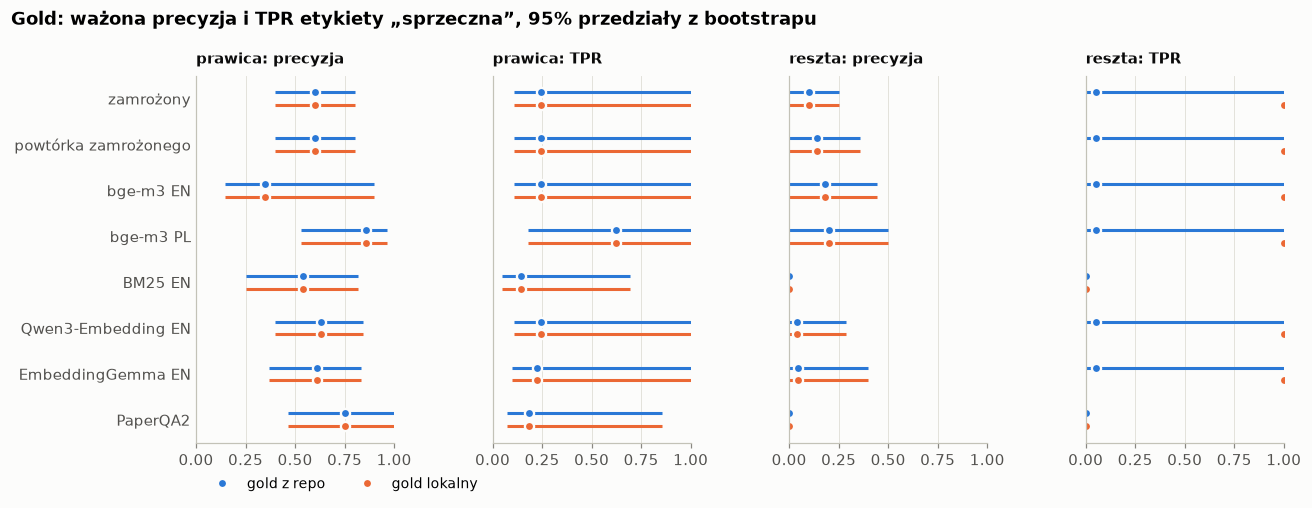

In [14]:
METRICS = [f"{g} etykieta {m}" for g in GROUPS for m in ("precyzja", "TPR")]
names = list(MS)
fig, axes = plt.subplots(1, 4, figsize=(12, 0.36 * len(names) + 1.8), sharey=True)
for ax, k in zip(axes, METRICS):
    for v, color, dy in (("z repo", ACCENT, -0.14), ("lokalny", SECOND, 0.14)):
        s = summary(v, [k])[k]
        y = np.arange(len(names)) + dy
        ax.hlines(y, s["2.5"], s["97.5"], color=color, lw=2)
        ax.plot(s["wartość"], y, "o", ms=6, color=color, mec=SURF, mew=1.5, label=f"gold {v}")
    ax.set_xlim(0, 1)
    ax.set_title(k.replace(" etykieta ", ": "), fontsize=10, pad=8)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(range(len(names)), names)
axes[0].set_ylim(len(names) - 0.5, -0.5)
fig.suptitle("Gold: ważona precyzja i TPR etykiety „sprzeczna”, 95% przedziały z bootstrapu", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.06), ncol=2, fontsize=9)
fig.tight_layout()
save(fig, "weryfikacja_02_gold")

Bez wag (gold z repo): zamrożony przebieg ma 26 fałszywych `sprzeczne` (14 trafień, 3 przeoczenia), warianty z jednym
rankingiem 12–21, PaperQA2 6, ale BM25 i PaperQA2 przeoczają więcej (10 i 8). Miary ważone zależą od kilku wypowiedzi z warstwy 2
(tabela w sekcji 7): #59 (prawica, waga 55,2) trafia tylko bge-m3 PL, stąd jego precyzja 0,86 i TPR 0,62 u prawicy;
#67 (prawica) jest fałszywie sprzeczna w bge-m3 EN (precyzja 0,35); #30 (reszta, waga 48,6) w Qwen3-Embedding
i EmbeddingGemmie (precyzja reszty 0,04). #36 i #94 nie łapie żaden przebieg. Przedział różnicy wobec zamrożonego nie
obejmuje 0 tylko przy precyzji prawicy w bge-m3 PL i TPR prawicy w BM25 (w goldzie lokalnym także przy TPR reszty
w BM25 i PaperQA2, które przeoczają obie sprzeczne wypowiedzi reszty, #4 i #97). Bootstrap obejmuje jednak tylko
losowość próby golda, a nie zmienność przebiegu: #59 ma inną etykietę w pełnym przebiegu zamrożonym i w jego
przebiegu `--ids` (sekcja 8). Wersja golda zmienia głównie TPR reszty (#94); #22 dokłada jeden fałszywy `sprzeczne`.

## 7. Gold: które wypowiedzi robią różnicę

Wypowiedzi, które są sprzeczne według golda albo według któregokolwiek przebiegu (1 = sprzeczna). Wagi warstwy 2
(ok. 49–55) są kilkanaście razy większe niż warstwy 1 (1,4–3), więc pojedyncza wypowiedź z warstwy 2 przesuwa miary
ważone bardziej niż wszystkie z warstwy 1 razem.

In [15]:
d = design[["kolejnosc", "grupa", "warstwa", "waga"]].copy()
for v, g in GOLD.items():
    d[f"gold {v}"] = E.arrays(g)["s"]
for n, ms in MS.items():
    d[n] = ms
flags = d.columns[4:]
d[d[flags].any(axis=1)].sort_values(["warstwa", "grupa", "kolejnosc"]).set_index("kolejnosc").round({"waga": 1})

,grupa,warstwa,waga,gold z repo,gold lokalny,zamrożony,powtórka zamrożonego,bge-m3 EN,bge-m3 PL,BM25 EN,Qwen3-Embedding EN,EmbeddingGemma EN,PaperQA2
kolejnosc,,,,,,,,,,,,,
3,prawica,1,3.0,0,0,1,1,1,1,1,1,1,0
7,prawica,1,3.0,1,1,1,1,1,1,1,1,1,0
14,prawica,1,3.0,0,0,1,1,1,1,1,1,1,1
15,prawica,1,3.0,1,1,1,1,1,1,1,1,1,1
20,prawica,1,3.0,1,1,1,1,1,1,1,1,1,1
23,prawica,1,3.0,1,1,1,1,1,1,0,1,1,1
27,prawica,1,3.0,1,1,1,1,1,1,0,1,1,1
37,prawica,1,3.0,1,1,1,1,1,1,1,1,1,1
41,prawica,1,3.0,0,0,1,1,1,1,1,1,1,1


W warstwie 1 zamrożony przebieg z definicji oznacza wszystkie wypowiedzi jako sprzeczne, a gold uznaje za sprzeczne
12 z 20 u prawicy i 2 z 20 u reszty (#4, #97). Pozostałe przebiegi usuwają część fałszywych `sprzeczne` reszty, ale
każdy inne. W warstwie 2 każda wypowiedź oznaczona inaczej niż w zamrożonym przesuwa wynik o 49–55 wypowiedzi
populacji.

## 8. Gold na twierdzeniach z ponownej ekstrakcji

Druga podstawa porównania: przebiegi `--ids` na całej próbie golda, z twierdzeniami wyciągniętymi od nowa tymi
samymi promptami (`claims_v1`), więc różnice wobec sekcji 6 pokazują też zmienność ekstrakcji. Tematyczność zostaje
z zamrożonego przebiegu. Ten przebieg mają tylko zamrożony RAG, EmbeddingGemma i PaperQA2.

In [16]:
def ids_run(verdicts_file):
    vd = pd.DataFrame(runs.last_lines(P / "verdicts" / verdicts_file, "twierdzenie_id").values())
    per = vd.groupby("wypowiedz_id")["werdykt"].agg(lambda x: int((x == "sprzeczne").any()))
    return design["wypowiedz_id"].map(per).fillna(0).to_numpy(int)


IDS = {
    FROZEN: "verdict_v1__gemma4_12b__sample.jsonl",
    "EmbeddingGemma EN": "verdict_v1__gemma4_12b__en_embeddinggemma_300m__sample.jsonl",
    "PaperQA2": "paperqa_v0__gemma4_12b__embeddinggemma_300m__sample.jsonl",
}
IDS = {n: ids_run(f) for n, f in IDS.items() if (P / "verdicts" / f).exists()}


def ids_table(g):
    a = E.arrays(g)
    rows = {}
    for n, ms in IDS.items():
        lab, s = (a["mt"] * ms).astype(bool), a["s"].astype(bool)
        rows[n] = {"model": int(lab.sum()), "TP": int((lab & s).sum()), "FP": int((lab & ~s).sum()),
                   "FN": int((~lab & s).sum()), **quality(a, ms)}
    return pd.DataFrame.from_dict(rows, orient="index")


for v, g in GOLD.items():
    print(f"gold {v}")
    display(ids_table(g).round(2))

gold z repo


,model,TP,FP,FN,prawica etykieta precyzja,prawica etykieta TPR,prawica werdykt precyzja,prawica werdykt TPR,reszta etykieta precyzja,reszta etykieta TPR,reszta werdykt precyzja,reszta werdykt TPR
zamrożony,29,14,15,3,0.84,0.62,0.91,0.62,0.10,0.03,0.20,0.03
EmbeddingGemma EN,31,14,17,3,0.67,0.25,0.86,0.25,0.04,0.05,0.05,0.05
PaperQA2,18,11,7,6,0.77,0.20,1.00,0.20,0.20,0.03,0.25,0.03


gold lokalny


,model,TP,FP,FN,prawica etykieta precyzja,prawica etykieta TPR,prawica werdykt precyzja,prawica werdykt TPR,reszta etykieta precyzja,reszta etykieta TPR,reszta werdykt precyzja,reszta werdykt TPR
zamrożony,29,14,15,2,0.84,0.62,0.91,0.62,0.10,0.5,0.20,0.5
EmbeddingGemma EN,31,14,17,2,0.67,0.25,0.86,0.25,0.04,1.0,0.05,1.0
PaperQA2,18,11,7,5,0.77,0.20,1.00,0.20,0.20,0.5,0.25,0.5


Na drugiej ekstrakcji zamrożone wyszukiwanie łapie #59 (przez inne twierdzenie niż w pełnym przebiegu), a EmbeddingGemma
i PaperQA2 nie, więc wynik na #59 zależy też od ekstrakcji, nie tylko od wyszukiwania.

## Podsumowanie (szkic)

- Zmiana wyszukiwania (bez RRF, inny embedding) zmienia udział `brak_podstaw` najwyżej o ok. 3–4 pp, a na goldzie nie
  daje poprawy, która odróżniałaby się od zmienności samego przebiegu; o wyniku decydują pojedyncze wypowiedzi
  z warstwy 2.
- PaperQA2 jest ostrożniejszy (6 fałszywych `sprzeczne` zamiast 26, ale 8 przeoczeń zamiast 3) i ok. 8 razy wolniejszy.
- Kierunek różnicy grup w etykietach modelu jest ten sam we wszystkich przebiegach; wynik kroku 7 od nich nie zależy.

Do decyzji:
1. Który przebieg traktować jako domyślny: EmbeddingGemma EN (domyślny w kodzie od `99b0ea4`, zgodny z uwagą
   prowadzącego, na goldzie nie lepszy), bge-m3 PL (najlepszy na goldzie, ale przez #59 i na modelu, który prowadzący
   uznał za za słaby) czy zostać przy zamrożonym jako wyniku głównym, a resztę opisać jako wrażliwość.
2. Czy zamiast dalszych zmian wyszukiwania sprawdzić, skąd bierze się `brak_podstaw`: np. losowe 50 twierdzeń
   z `brak_podstaw` i ocena, czy w AR6 jest ustalenie, które by je rozstrzygało (przeoczenie wyszukiwania) czy nie
   (twierdzenie poza zakresem AR6).
3. Czy kolejne zmiany oceniać na nowym zbiorze spoza golda, bo obecny gold był już oglądany przy analizie błędów.